# Survey Data Analysis
This notebook performs an exploratory analysis on survey results, covering data cleaning, encoding, user engagement metrics, and normalization strategies.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../Survey_Results_UC.csv")

print(f"Dataset Shape: {df.shape}")
print("First 5 rows:")
display(df.head())

Dataset Shape: (96, 61)
First 5 rows:


,id. Response ID,T01. Artificial Intelligence will improve society more than it will create problems.,T02. Generative AI tools should be allowed as learning aids in higher education.,T03. Students should disclose the use of AI in assignments and reports.,T04. Every engineering student should receive formal education in AI.,T05. Artificial Intelligence will significantly accelerate scientific discovery.,T06. Most repetitive jobs will eventually be replaced by intelligent automation.,T07. Robots should replace humans in hazardous occupations whenever possible.,T08. AI-assisted diagnosis should become routine in healthcare.,T09. Autonomous vehicles will ultimately make transportation safer.,...,"V06. Water conservation should be a priority in households, institutions, and industries.",V07. Protecting biodiversity is essential for long-term human well-being.,V08. Universities should adopt environmentally sustainable campus practices even if implementation costs increase.,"V09. Products should be designed to encourage reuse, repair, and recycling.",V10. Consumers should consider environmental impact when purchasing products.,V11. Technological innovation is essential for addressing environmental challenges.,V12. Environmental sustainability should be integrated into higher education curricula.,V13. Companies should be held accountable for the environmental impacts of their activities.,V14. International cooperation is necessary to effectively address environmental challenges.,V15. Current generations have a responsibility to protect natural resources for future generations.
0,11,Agree,Agree,Neutral,Strongly Agree,Strongly Agree,Agree,Agree,Disagree,Neutral,...,Neutral,Agree,Neutral,Strongly Agree,Neutral,Neutral,Neutral,Agree,Agree,Neutral
1,12,Agree,Agree,Strongly Agree,Agree,Neutral,Agree,Agree,Disagree,Neutral,...,Agree,Agree,Agree,Agree,Neutral,Agree,Agree,Agree,Agree,Agree
2,13,Agree,Strongly Agree,Neutral,Disagree,Strongly Agree,Agree,Strongly Agree,Agree,Neutral,...,Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Strongly Agree,Agree,Strongly Agree,Strongly Agree,Agree
3,14,Neutral,Agree,Neutral,Agree,Agree,Agree,Neutral,Agree,Disagree,...,Agree,Agree,Agree,Agree,Agree,Agree,Agree,Strongly Agree,Strongly Agree,Agree
4,16,Neutral,Agree,Strongly Agree,Strongly Agree,Strongly Disagree,Strongly Agree,Strongly Agree,Agree,Neutral,...,Agree,Strongly Agree,Agree,Strongly Agree,Neutral,Agree,Neutral,Strongly Agree,Strongly Agree,Agree


## Data Preprocessing
Map the categorical Likert responses (e.g., 'Strongly Agree') to a numerical scale from -2 to 2 for quantitative analysis.

In [ ]:
import pandas as pd
import numpy as np

# Define mapping for encoding Likert responses
encode_map = {
    "Strongly Agree": 2,
    "Agree": 1,
    "Neutral": 0,
    "Disagree": -1,
    "Strongly Disagree": -2,
    "No Comments": np.nan,
    "": np.nan
}

# Assume the first column is the Respondent ID
id_col = df.columns[0]
df_encoded = df.set_index(id_col)

df_encoded = df_encoded.apply(lambda col: col.map(encode_map))

# Convert all response columns to numeric type
df_encoded = df_encoded.apply(pd.to_numeric, errors='coerce')

## User Engagement and Response Distribution
Analyze how many questions users skipped and look at the overall frequency of different response levels across the entire dataset.

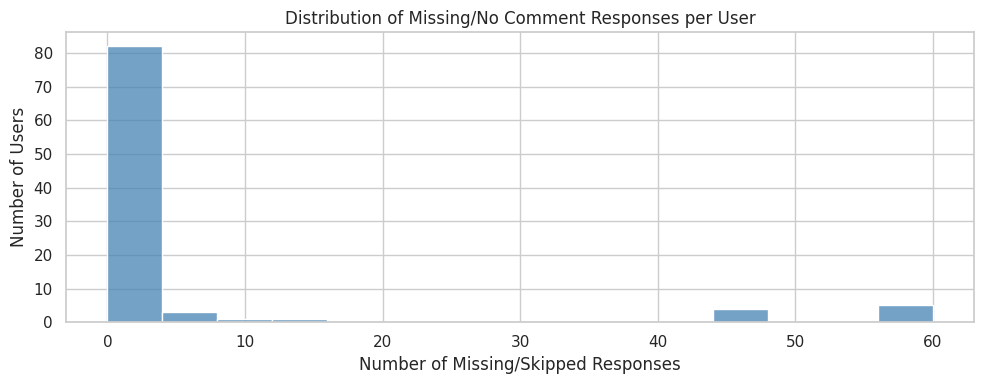

Average user engagement score: 90.59%


In [ ]:
plt.figure(figsize=(10, 4))
missing_per_user = df_encoded.isna().sum(axis=1)

sns.histplot(missing_per_user, bins=15, kde=False, color='steelblue')
plt.title("Distribution of Missing/No Comment Responses per User")
plt.xlabel("Number of Missing/Skipped Responses")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

# Calculate proposed engagement score
engagement_scores = 1 - (missing_per_user / df_encoded.shape[1])
print(f"Average user engagement score: {engagement_scores.mean():.2%}")

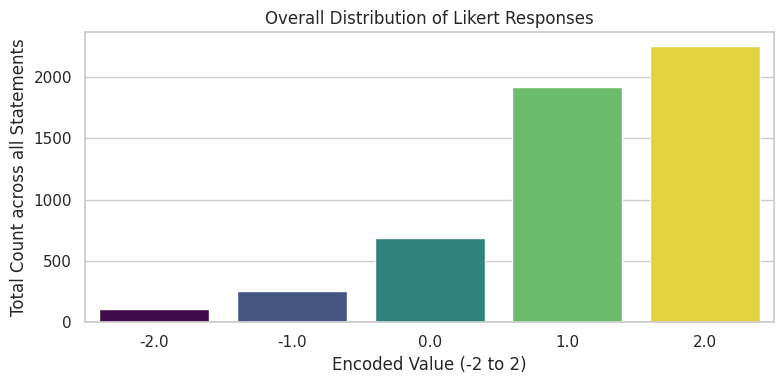

In [ ]:
plt.figure(figsize=(8, 4))
all_responses = df_encoded.values.flatten()
valid_responses = all_responses[~np.isnan(all_responses)]

sns.countplot(x=valid_responses, hue=valid_responses, palette="viridis", legend=False)

plt.title("Overall Distribution of Likert Responses")
plt.xlabel("Encoded Value (-2 to 2)")
plt.ylabel("Total Count across all Statements")
plt.tight_layout()
plt.show()

## Data Scaling and Normalization
To account for individual biases (like extreme responding or central tendency), we explore different scaling methods to determine which best preserves the signal for downstream tasks.

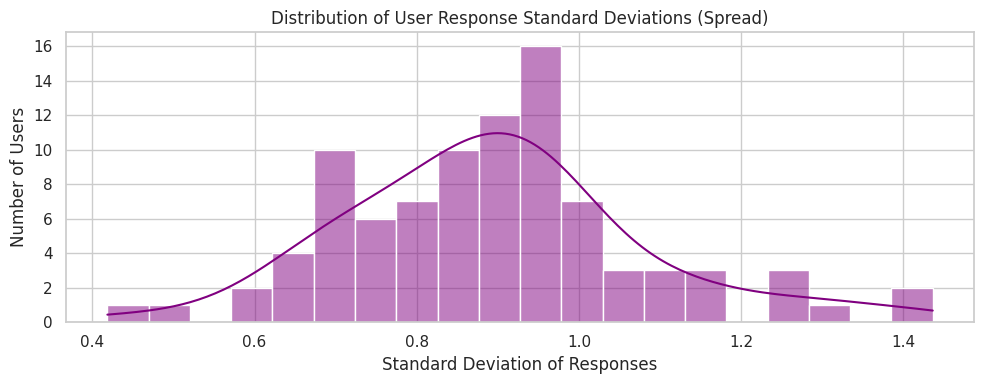

In [ ]:
plt.figure(figsize=(10, 4))
user_std = df_encoded.std(axis=1)

sns.histplot(user_std, bins=20, kde=True, color='purple')
plt.title("Distribution of User Response Standard Deviations (Spread)")
plt.xlabel("Standard Deviation of Responses")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

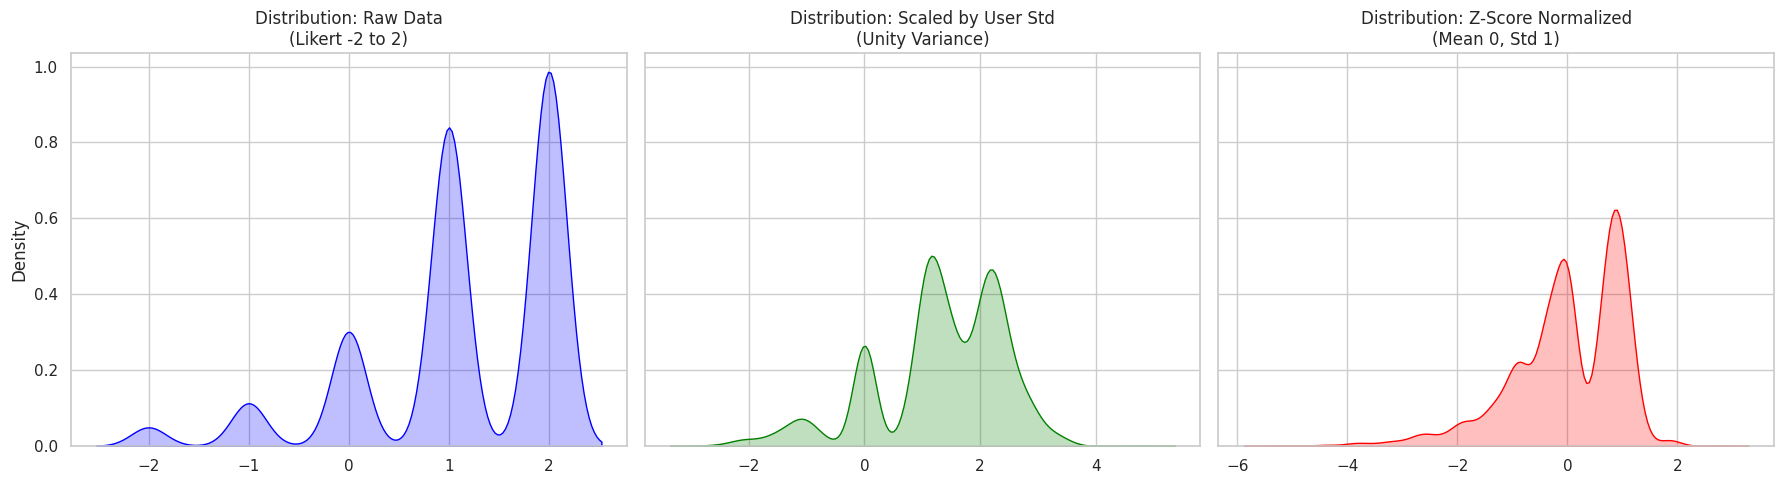

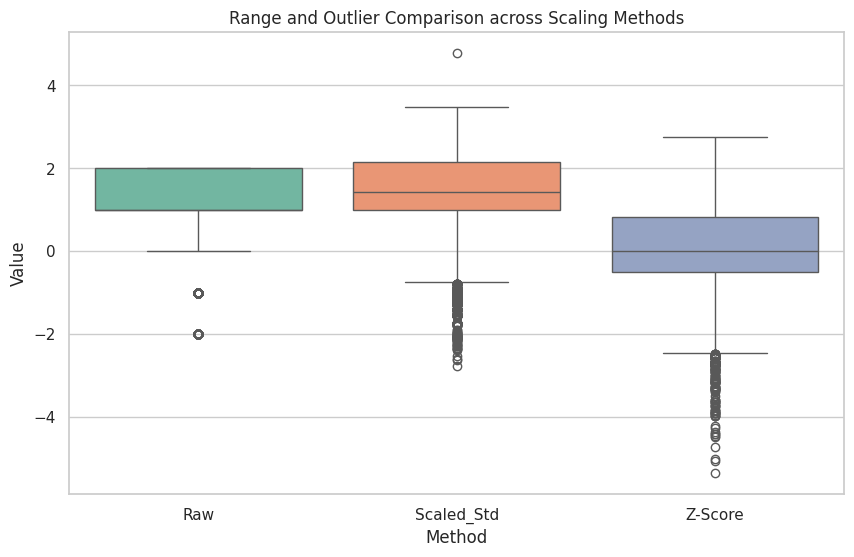

In [ ]:
from sklearn.preprocessing import StandardScaler

# 1. Raw Data (df_encoded)
# 2. Scaled by Std Dev (df_rescaled)
# 3. Z-score Normalization (StandardScaler)

df_rescaled = df_encoded.div(df_encoded.std(axis=1), axis=0)

scaler = StandardScaler()
df_zscore = pd.DataFrame(
    scaler.fit_transform(df_encoded.fillna(df_encoded.mean())),
    index=df_encoded.index,
    columns=df_encoded.columns
)

# Comparison Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

sns.kdeplot(df_encoded.values.flatten(), ax=axes[0], fill=True, color='blue')
axes[0].set_title("Distribution: Raw Data\n(Likert -2 to 2)")

sns.kdeplot(df_rescaled.values.flatten(), ax=axes[1], fill=True, color='green')
axes[1].set_title("Distribution: Scaled by User Std\n(Unity Variance)")

sns.kdeplot(df_zscore.values.flatten(), ax=axes[2], fill=True, color='red')
axes[2].set_title("Distribution: Z-Score Normalized\n(Mean 0, Std 1)")

plt.tight_layout()
plt.show()

# Boxplot comparison to see outliers/spread clearly
plt.figure(figsize=(10, 6))
comparison_data = pd.DataFrame({
    'Raw': df_encoded.values.flatten(),
    'Scaled_Std': df_rescaled.values.flatten(),
    'Z-Score': df_zscore.values.flatten()
}).melt(var_name='Method', value_name='Value')

sns.boxplot(x='Method', y='Value', hue='Method', data=comparison_data, palette='Set2', legend=False)
plt.title("Range and Outlier Comparison across Scaling Methods")
plt.show()

## Thematic Category Correlations
Finally, we visualize the internal consistency and relationships between statements within each survey category using correlation heatmaps.

Detected categories: ['E', 'S', 'T', 'V']


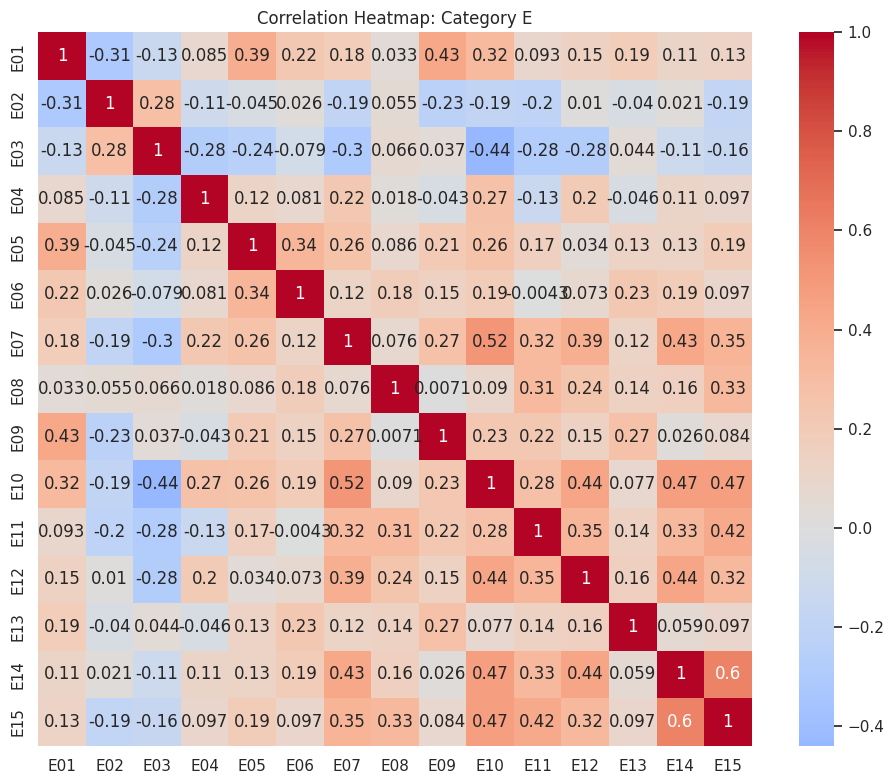

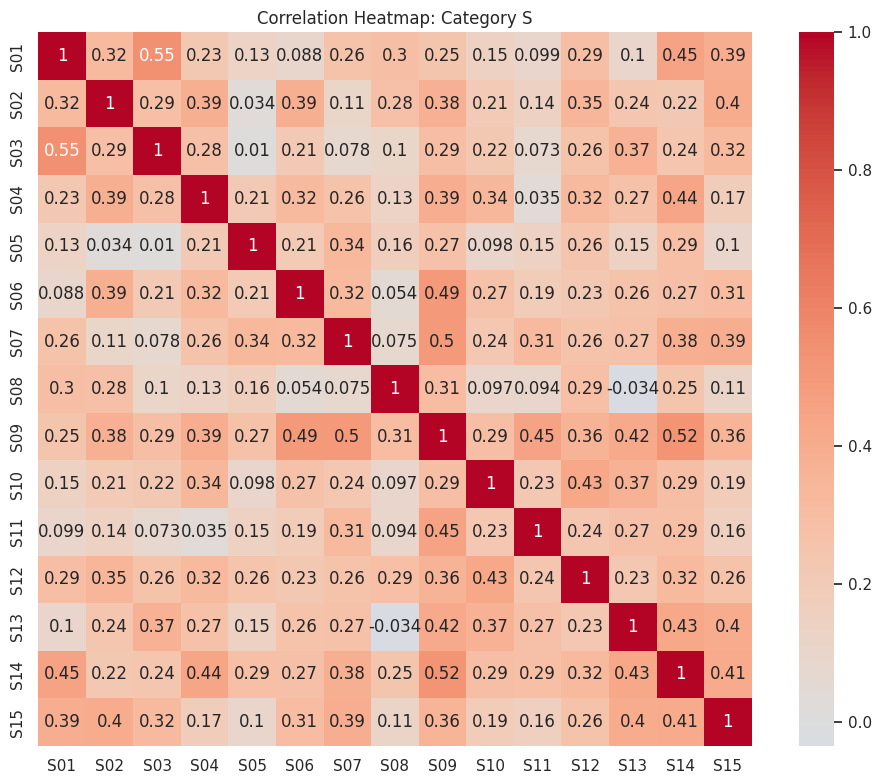

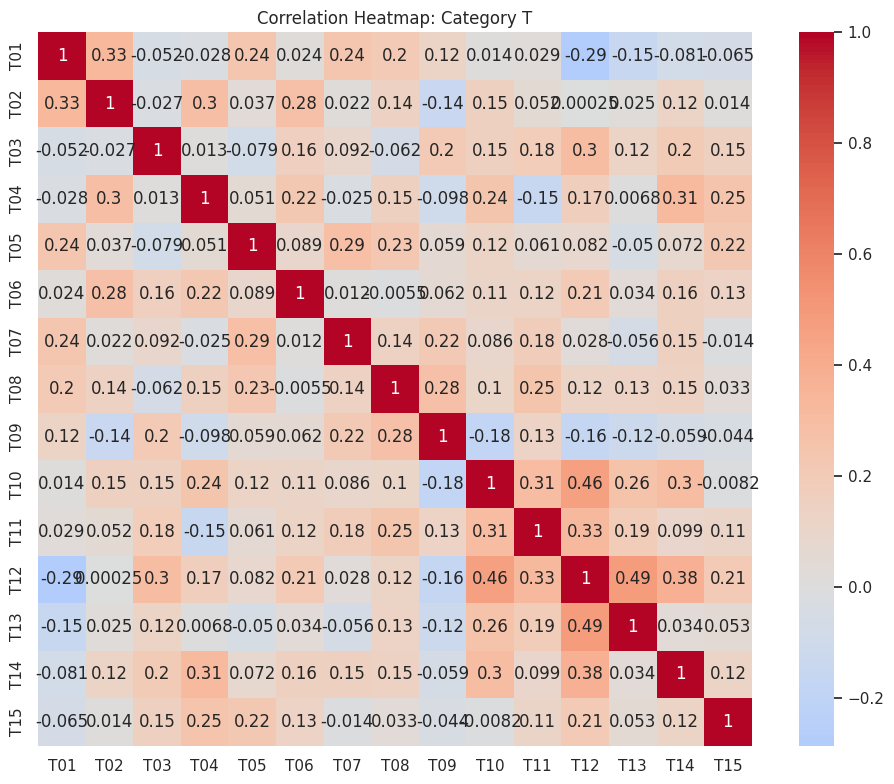

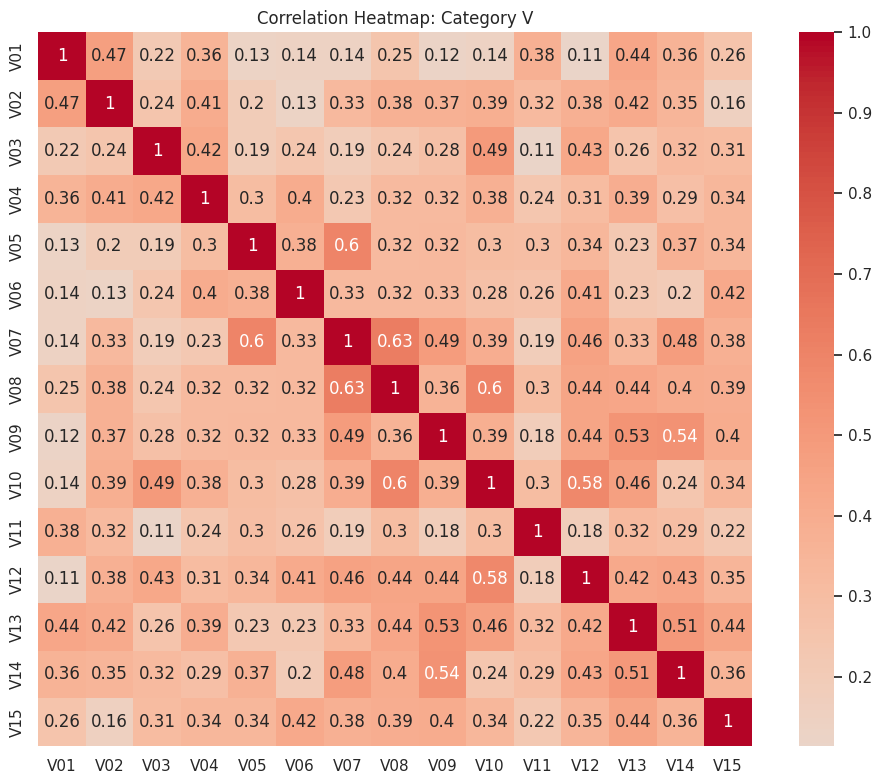

In [ ]:
import re

# Identify all unique categories based on the prefix (e.g., 'T', 'S', etc.)
all_cols = df_encoded.columns
prefixes = sorted(list(set([re.match(r'^([a-zA-Z]+)', str(col)).group(1) for col in all_cols if re.match(r'^([a-zA-Z]+)', str(col))])))

print(f"Detected categories: {prefixes}")

# Loop through each category and generate a heatmap
for prefix in prefixes:
    cat_cols = [col for col in all_cols if str(col).startswith(prefix)]

    if len(cat_cols) > 1: # Only plot if there's more than one statement to correlate
        plt.figure(figsize=(10, 8))
        correlation_matrix = df_encoded[cat_cols].corr()

        # Create short labels using the first 3 characters
        short_labels = [str(col)[:3] for col in cat_cols]

        ax = sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True,
                         xticklabels=short_labels, yticklabels=short_labels)

        plt.title(f"Correlation Heatmap: Category {prefix}")
        plt.tight_layout()
        plt.show()
    else:
        print(f"Category {prefix} only has one column, skipping heatmap.")